<a href="https://colab.research.google.com/github/HKozuka/IDX-Exchange-Data-Science/blob/main/05_generalized_additive_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDX Exchange: Predicting Home Prices with a Generalized Additive Model (GAM)

This notebook predicts `log_ClosePrice` for California single-family sales with a GAM, then opens the model up to show what it learned. It is written so someone new to GAMs can follow it from top to bottom.

**The idea in one line.** Linear regression fits one straight-line slope per feature:

$$\log(\text{price}) = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots$$

A GAM swaps each slope for a smooth curve that the data shapes:

$$\log(\text{price}) = \beta_0 + f_1(\text{living area}) + f_2(\text{property age}) + f_3(\text{lat}, \text{lon}) + \dots$$

**Why that is useful**
- **Flexible:** each $f$ can bend, for example a size premium that flattens out for very large homes.
- **Readable:** the pieces simply add up, so each $f$ can be plotted on its own to show how one feature moves the price while everything else is held fixed (Section 7). A random forest can't be read this way.
- **The trade-off:** because the pieces add, a GAM does not learn on its own that an extra 500 sqft is worth more in Palo Alto than in Fresno. That is the main reason tree models can score somewhat higher.

**Because the target is a log, effects read as percentages.** An effect of +0.10 on log price means the price is multiplied by $e^{0.10} \approx 1.105$, about **+10.5%**. Every plot in Section 7 is converted to % this way.

**Roadmap:** 1 Setup, 2 Look at the data, 3 Prepare the data, 4 Pick a term type per feature, 5 Hyperparameters, 6 Fit and evaluate, 7 Read the model, 8 Takeaways.

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q pygam
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from pygam import LinearGAM, s, f, l, te
from sklearn.metrics import r2_score, mean_squared_error

# Plot styling used throughout: one series color, quiet gray ink for axes and reference lines
BLUE, INK = '#2a78d6', '#52514e'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e5e1', 'grid.linewidth': 0.6, 'axes.edgecolor': INK})

In [ ]:
BASE_PATH = '/content/drive/MyDrive/IDX Exchange Data Science Internship/Google Colab Notebooks/'
TARGET = 'log_ClosePrice'
SEED = 42

df_clean = pd.read_csv(f'{BASE_PATH}X_after_feat_engin.csv')                 # training source
df_test_raw = pd.read_csv(f'{BASE_PATH}test_dataset_after_feat_eng.csv')     # holdout
print('df_clean:', df_clean.shape, '| test:', df_test_raw.shape)
df_clean.head()

df_clean: (307648, 48) | test: (12401, 47)


,Unnamed: 0,log_ClosePrice,CloseDate,ViewYN,WaterfrontYN,PoolPrivateYN,Stories,FireplaceYN,AssociationFeeFrequency,log_LivingArea,...,SqftPerBedroom,Zip_ppsf_6m,Zip_sales_6m,Nbhd_ppsf_6m,Nbhd_logprice_est,Comp_ppsf,Comp_logprice_est,Comp_size_diff,Comp_dist_km,CoastDist_km
0,0,13.610943,2024-01-05,0.0,0.0,0.0,2.0,0.0,NaN,7.588324,...,493.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2.125725
1,1,13.604790,2024-01-05,0.0,0.0,0.0,2.0,0.0,NaN,7.588324,...,493.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,2.102132
2,2,14.557448,2024-01-02,1.0,0.0,0.0,2.0,1.0,NaN,8.226038,...,934.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,12.654789
3,3,14.665661,2024-01-31,1.0,0.0,0.0,1.0,1.0,NaN,7.800982,...,610.5,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,26.790793
4,4,13.873779,2024-01-16,1.0,0.0,0.0,1.0,1.0,NaN,7.559038,...,639.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,26.995806


## 2. Look at the data

A GAM is sensitive to three things, so check them first:
1. **Column types.** A GAM only takes numbers, so text and dates have to be converted or dropped.
2. **Missing values.** pyGAM can't handle NaN.
3. **Extreme values and long tails.** These waste the curve's flexibility (Section 3 explains why).

The second cell also checks for **redundant columns**. Two near-identical features make a GAM split one effect between two curves in an arbitrary way, so neither curve can be trusted on its own. This is the GAM version of multicollinearity, called *concurvity*.

In [ ]:
pd.set_option('display.max_rows', 100)
summary = pd.DataFrame({'dtype': df_clean.dtypes, 'n_unique': df_clean.nunique(), 'n_missing': df_clean.isna().sum(),
                        'min': df_clean.min(numeric_only=True), 'max': df_clean.max(numeric_only=True)})
summary

,dtype,n_unique,n_missing,min,max
AssociationFee,float64,2743,0,0.000000e+00,20712.000000
AssociationFeeFrequency,object,4,230196,NaN,NaN
BathroomsTotalInteger,float64,15,0,1.000000e+00,15.000000
BedBathRatio,float64,76,0,2.500000e-01,7.500000
BedroomsTotal,float64,15,0,1.000000e+00,15.000000
City,object,1090,0,NaN,NaN
CloseDate,object,845,0,NaN,NaN
CoastDist_km,float64,296292,0,1.640711e-04,379.068483
Comp_dist_km,float64,274167,31555,0.000000e+00,219.323388
Comp_logprice_est,float64,270140,31555,1.122215e+01,16.790304


In [ ]:
# Long tails: look at how far the max sits from the 99th percentile
skew_cols = ['GarageSpaces', 'LotCoverage', 'HOA_Monthly', 'CoastDist_km', 'Comp_dist_km', 'ElemSchoolDist_m',
             'MiddleSchoolDist_m', 'HighSchoolDist_m', 'SqftPerBedroom', 'Zip_sales_6m', 'log_LotSizeSquareFeet']
print(df_clean[skew_cols].quantile([0, .01, .5, .99, 1]).T.round(2).to_string(), '\n')

# Redundant pairs: correlations near 1 (or -1) mean one column adds nothing
pairs = [('YearBuilt', 'PropertyAge'), ('Nbhd_ppsf_6m', 'Zip_ppsf_6m'), ('Comp_logprice_est', 'Nbhd_logprice_est'),
         ('log_BuildingAreaTotal', 'log_LivingArea'), ('AssociationFee', 'HOA_Monthly')]
for a, b in pairs:
    print(f'corr({a}, {b}) = {df_clean[a].corr(df_clean[b]):.3f}')

                        0.00    0.01     0.50      0.99       1.00
GarageSpaces            0.00    0.00     2.00      4.00     600.00
LotCoverage             0.00    0.01     0.24      0.98  238600.00
HOA_Monthly             0.00    0.00     0.00    609.00    5553.00
CoastDist_km            0.00    0.49    24.45    172.34     379.07
Comp_dist_km            0.00    0.12     0.41      6.38     219.32
ElemSchoolDist_m        0.83  120.90   837.35   7482.38  105406.91
MiddleSchoolDist_m      6.95  249.71  1871.12  17143.23  130749.49
HighSchoolDist_m        0.35  269.19  1958.78  14883.44  130749.49
SqftPerBedroom         91.75  300.75   539.50   1236.50    8050.00
Zip_sales_6m            0.00    0.00    77.00    383.00     555.00
log_LotSizeSquareFeet   0.00    7.50     8.89     12.39      21.46 

corr(YearBuilt, PropertyAge) = -1.000
corr(Nbhd_ppsf_6m, Zip_ppsf_6m) = 1.000
corr(Comp_logprice_est, Nbhd_logprice_est) = 0.975
corr(log_BuildingAreaTotal, log_LivingArea) = 0.303
corr(Associat

## 3. Prepare the data for a GAM

| Step | Why a GAM needs it |
|---|---|
| Keep CA rows only | A handful of AZ/NV/ME rows would sit far outside the location map. |
| Use `CloseDate` only to split train/test by time, then drop it | `CloseDate` is kept in `df_clean` to preserve time order (for the split here, or for time-ordered k-fold validation). It is not a model feature. |
| Drop IDs and free text (`Unnamed: 0`, `UnparsedAddress`) and constants | They carry no signal. |
| Drop `City`, `PostalCode` | 1,000+ levels each. Location comes from the lat/lon surface and `GeoCluster` instead. |
| Drop redundant columns (`YearBuilt`, `Zip_ppsf_6m`, `Nbhd_logprice_est`, `AssociationFee`, `log_PropertyAge`) | Concurvity: see Section 2. `log_BuildingAreaTotal` is dropped because it agrees poorly with living area (corr 0.30). |
| Cap impossible values (600 garage spaces, lot coverage above 100%) and log-transform long tails | pyGAM spreads each curve's knots **evenly between the min and the max**. One extreme value means almost every knot covers empty space, and the curve can't bend where the homes actually are. |
| Flag missing values, then fill gaps with **training** medians | pyGAM can't take NaN, so gaps have to be filled. A 0/1 flag per gap pattern lets the model learn whether homes with filled-in values sell differently, instead of treating the median as a real value. Columns missing on the same rows share one flag (the comp and neighborhood columns are all missing for the same homes). Columns with fewer than 100 gaps are filled without a flag. Training medians keep test data out of training. |

In [ ]:
# CloseDate is used only here, to keep the split in time order. It is not a model feature.
key = ['UnparsedAddress', 'CloseDate']
overlap = df_test_raw.merge(df_clean[key].drop_duplicates(), on=key, how='inner')
print(f'Test rows also in df_clean: {len(overlap):,} of {len(df_test_raw):,} '
      f'(close dates {df_test_raw.CloseDate.min()} to {df_test_raw.CloseDate.max()})')
train_source = df_clean[pd.to_datetime(df_clean['CloseDate']) < '2026-04-01']

DROP_COLS = ['Unnamed: 0', 'UnparsedAddress', 'SchoolRating_missing', 'StateOrProvince', 'City', 'PostalCode',
             'CloseDate', 'ListingContractDate', 'AssociationFeeFrequency', 'AssociationFee', 'YearBuilt',
             'log_PropertyAge', 'Zip_ppsf_6m', 'Nbhd_logprice_est', 'log_BuildingAreaTotal']
LOG1P_COLS = ['ElemSchoolDist_m', 'MiddleSchoolDist_m', 'HighSchoolDist_m', 'CoastDist_km',
              'Comp_dist_km', 'HOA_Monthly', 'Zip_sales_6m']

def prepare_for_gam(df):
    out = df[df['StateOrProvince'] == 'CA'].copy()
    out = out.drop(columns=[c for c in DROP_COLS if c in out.columns])

    out['GarageSpaces'] = out['GarageSpaces'].clip(upper=10)
    out['LotCoverage'] = out['LotCoverage'].clip(upper=1)
    out['log_LotSizeSquareFeet'] = out['log_LotSizeSquareFeet'].clip(np.log(500), np.log(43560 * 100))  # 500 sqft to 100 acres
    out['SqftPerBedroom'] = out['SqftPerBedroom'].clip(upper=3000)
    for col in LOG1P_COLS:
        out['log1p_' + col] = np.log1p(out.pop(col))
    return out

train_gam, test_gam = prepare_for_gam(train_source), prepare_for_gam(df_test_raw)
X_train, y_train = train_gam.drop(columns=TARGET), train_gam[TARGET]
X_test, y_test = test_gam.drop(columns=TARGET), test_gam[TARGET]

# Flag missing values BEFORE filling them, so the model can tell a filled-in value from a real one.
# Columns missing on exactly the same rows share one flag (identical flags would be redundant).
# Columns with fewer than MIN_MISSING gaps are only filled: a flag on a handful of homes can't be estimated.
MIN_MISSING = 100
flag_groups = {}
for c in X_train.columns[X_train.isna().sum() >= MIN_MISSING]:
    flag_groups.setdefault(X_train[c].isna().values.tobytes(), []).append(c)
MISSING_FLAGS = []
for cols in flag_groups.values():
    name = 'Comp_missing' if 'Comp_logprice_est' in cols else f'{cols[0]}_missing'
    X_train[name] = X_train[cols[0]].isna().astype(int)
    X_test[name] = X_test[cols[0]].isna().astype(int)
    MISSING_FLAGS.append(name)

na_report = pd.DataFrame({'missing (train)': train_gam.drop(columns=TARGET).isna().sum(),
                          'missing (test)': test_gam.drop(columns=TARGET).isna().sum()})
na_report = na_report[na_report.sum(axis=1) > 0]
na_report['flag'] = [next((n for n, cols in zip(MISSING_FLAGS, flag_groups.values()) if c in cols), 'none (filled only)')
                     for c in na_report.index]

# Then fill every gap with the TRAINING median
train_medians = X_train.median()
X_train, X_test = X_train.fillna(train_medians), X_test.fillna(train_medians)
print(f'Train: {X_train.shape} | Test: {X_test.shape} | Missing values left: {X_train.isna().sum().sum() + X_test.isna().sum().sum()}')
print('Missing-value flags added:', MISSING_FLAGS)
na_report

Test rows also in df_clean: 12,401 of 12,401 (close dates 2026-04-01 to 2026-04-30)
Train: (295241, 34) | Test: (12400, 34) | Missing values left: 0
Missing-value flags added: ['LotCoverage_missing', 'Comp_missing']


,missing (train),missing (test),flag
LotCoverage,150,11,LotCoverage_missing
Nbhd_ppsf_6m,31552,2,Comp_missing
Comp_ppsf,31552,2,Comp_missing
Comp_logprice_est,31552,2,Comp_missing
Comp_size_diff,31552,2,Comp_missing
log1p_Comp_dist_km,31552,2,Comp_missing
log1p_Zip_sales_6m,2,2,none (filled only)


## 4. Pick a term type for each feature

A GAM is built from four kinds of pieces. Each feature gets the one that matches what it is.

<img alt="The four GAM term types: s() smooth spline, te() tensor surface, f() factor, l() linear" width="100%" src="data:image/svg+xml;utf8,%3Csvg xmlns='http://www.w3.org/2000/svg' width='960' height='268' viewBox='0 0 960 268' font-family='Helvetica,Arial,sans-serif'%3E%3Crect width='960' height='268' fill='%23fcfcfb'/%3E%3Ctext x='30' y='28' font-size='17' font-weight='700' fill='%230b0b0b'%3Es()  smooth spline%3C/text%3E%3Ctext x='30' y='48' font-size='12.5' fill='%2352514e'%3Eweighted bumps add up to one curve%3C/text%3E%3Ctext x='30' y='256' font-size='12' fill='%2352514e' font-style='italic'%3Ee.g. living area, school score%3C/text%3E%3Cline x1='35' y1='220' x2='235' y2='220' stroke='%2352514e'/%3E%3Cline x1='35' y1='70' x2='35' y2='220' stroke='%2352514e'/%3E%3Ctext x='135' y='236' font-size='11' fill='%2352514e' text-anchor='middle'%3Efeature value%3C/text%3E%3Ctext x='29' y='145' font-size='11' fill='%2352514e' text-anchor='middle' transform='rotate(-90 29 145)'%3Eeffect on price%3C/text%3E%3Cpath d='M43.0,202.0 L46.8,202.2 L50.5,202.7 L54.3,203.4 L58.0,204.2 L61.8,205.1 L65.5,205.9 L69.3,206.5 L73.0,207.1 L76.8,207.4 L80.6,207.7 L84.3,207.8 L88.1,207.9 L91.8,208.0 L95.6,208.0' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M43.0,202.4 L46.8,199.3 L50.5,195.2 L54.3,190.3 L58.0,184.8 L61.8,179.3 L65.5,174.5 L69.3,171.1 L73.0,169.6 L76.8,170.4 L80.6,173.2 L84.3,177.6 L88.1,182.9 L91.8,188.5 L95.6,193.6 L99.3,198.1 L103.1,201.5 L106.8,204.0 L110.6,205.7 L114.3,206.7 L118.1,207.3 L121.9,207.7 L125.6,207.8' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M50.5,207.9 L54.3,207.7 L58.0,207.4 L61.8,206.8 L65.5,205.7 L69.3,203.9 L73.0,201.2 L76.8,197.4 L80.6,192.2 L84.3,185.9 L88.1,178.7 L91.8,171.5 L95.6,164.9 L99.3,160.1 L103.1,157.8 L106.8,158.2 L110.6,161.5 L114.3,167.0 L118.1,173.8 L121.9,181.2 L125.6,188.1 L129.4,194.1 L133.1,198.8 L136.9,202.3 L140.6,204.6 L144.4,206.1 L148.1,207.0 L151.9,207.5 L155.7,207.8 L159.4,207.9' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M80.6,207.9 L84.3,207.8 L88.1,207.6 L91.8,207.2 L95.6,206.5 L99.3,205.4 L103.1,203.5 L106.8,200.9 L110.6,197.4 L114.3,193.0 L118.1,188.0 L121.9,182.7 L125.6,178.0 L129.4,174.3 L133.1,172.3 L136.9,172.3 L140.6,174.3 L144.4,178.0 L148.1,182.7 L151.9,188.0 L155.7,193.0 L159.4,197.4 L163.2,200.9 L166.9,203.5 L170.7,205.4 L174.4,206.5 L178.2,207.2 L181.9,207.6 L185.7,207.8 L189.4,207.9' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M110.6,207.9 L114.3,207.8 L118.1,207.6 L121.9,207.1 L125.6,206.3 L129.4,204.9 L133.1,202.8 L136.9,199.7 L140.6,195.4 L144.4,190.0 L148.1,183.7 L151.9,177.1 L155.7,170.9 L159.4,165.9 L163.2,163.0 L166.9,162.5 L170.7,164.7 L174.4,169.0 L178.2,174.9 L181.9,181.5 L185.7,188.0 L189.4,193.7 L193.2,198.4 L197.0,201.9 L200.7,204.3 L204.5,205.9 L208.2,206.9 L212.0,207.4 L215.7,207.7 L219.5,207.9' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M144.4,207.9 L148.1,207.7 L151.9,207.4 L155.7,206.8 L159.4,205.8 L163.2,204.2 L166.9,201.9 L170.7,198.7 L174.4,194.5 L178.2,189.7 L181.9,184.5 L185.7,179.5 L189.4,175.3 L193.2,172.7 L197.0,172.0 L200.7,173.4 L204.5,176.6 L208.2,181.1 L212.0,186.2 L215.7,191.4 L219.5,196.0 L223.2,199.9 L227.0,202.8' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cpath d='M174.4,207.8 L178.2,207.6 L181.9,207.2 L185.7,206.4 L189.4,205.0 L193.2,202.8 L197.0,199.5 L200.7,194.9 L204.5,188.9 L208.2,181.8 L212.0,174.0 L215.7,166.4 L219.5,159.9 L223.2,155.5 L227.0,154.0' fill='none' stroke='%239fc3ee' stroke-width='1.2'/%3E%3Cg fill='%2352514e' fill-opacity='0.35'%3E%3Ccircle cx='43' cy='197' r='2.2'/%3E%3Ccircle cx='82' cy='162' r='2.2'/%3E%3Ccircle cx='104' cy='147' r='2.2'/%3E%3Ccircle cx='143' cy='162' r='2.2'/%3E%3Ccircle cx='193' cy='166' r='2.2'/%3E%3Ccircle cx='173' cy='148' r='2.2'/%3E%3Ccircle cx='169' cy='144' r='2.2'/%3E%3Ccircle cx='192' cy='173' r='2.2'/%3E%3Ccircle cx='213' cy='155' r='2.2'/%3E%3Ccircle cx='149' cy='154' r='2.2'/%3E%3Ccircle cx='111' cy='143' r='2.2'/%3E%3Ccircle cx='104' cy='151' r='2.2'/%3E%3Ccircle cx='122' cy='144' r='2.2'/%3E%3Ccircle cx='146' cy='154' r='2.2'/%3E%3Ccircle cx='54' cy='197' r='2.2'/%3E%3Ccircle cx='137' cy='155' r='2.2'/%3E%3Ccircle cx='210' cy='164' r='2.2'/%3E%3Ccircle cx='106' cy='141' r='2.2'/%3E%3Ccircle cx='138' cy='170' r='2.2'/%3E%3Ccircle cx='95' cy='158' r='2.2'/%3E%3Ccircle cx='104' cy='153' r='2.2'/%3E%3Ccircle cx='86' cy='157' r='2.2'/%3E%3Ccircle cx='202' cy='161' r='2.2'/%3E%3Ccircle cx='138' cy='161' r='2.2'/%3E%3Ccircle cx='216' cy='152' r='2.2'/%3E%3C/g%3E%3Cpath d='M43.0,196.4 L46.8,193.4 L50.5,189.7 L54.3,185.3 L58.0,180.4 L61.8,175.1 L65.5,170.1 L69.3,165.6 L73.0,161.9 L76.8,159.1 L80.6,156.9 L84.3,155.1 L88.1,153.1 L91.8,151.1 L95.6,149.1 L99.3,147.5 L103.1,146.8 L106.8,147.1 L110.6,148.4 L114.3,150.5 L118.1,152.7 L121.9,154.7 L125.6,156.2 L129.4,157.2 L133.1,157.8 L136.9,158.2 L140.6,158.2 L144.4,157.9 L148.1,157.2 L151.9,155.9 L155.7,154.4 L159.4,153.0 L163.2,152.1 L166.9,151.9 L170.7,152.6 L174.4,153.9 L178.2,155.4 L181.9,156.7 L185.7,157.6 L189.4,158.0 L193.2,157.9 L197.0,157.4 L200.7,156.6 L204.5,155.4 L208.2,153.7 L212.0,151.7 L215.7,149.5 L219.5,147.8 L223.2,147.3 L227.0,148.7' fill='none' stroke='%232a78d6' stroke-width='2.5'/%3E%3Ctext x='270' y='28' font-size='17' font-weight='700' fill='%230b0b0b'%3Ete()  tensor surface%3C/text%3E%3Ctext x='270' y='48' font-size='12.5' fill='%2352514e'%3Eone smooth surface over two features%3C/text%3E%3Ctext x='270' y='256' font-size='12' fill='%2352514e' font-style='italic'%3Ee.g. latitude x longitude%3C/text%3E%3Cline x1='275' y1='220' x2='475' y2='220' stroke='%2352514e'/%3E%3Cline x1='275' y1='70' x2='275' y2='220' stroke='%2352514e'/%3E%3Ctext x='375' y='236' font-size='11' fill='%2352514e' text-anchor='middle'%3Efeature A (longitude)%3C/text%3E%3Ctext x='269' y='145' font-size='11' fill='%2352514e' text-anchor='middle' transform='rotate(-90 269 145)'%3Efeature B (latitude)%3C/text%3E%3Crect x='275.0' y='205.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='275.0' y='190.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='275.0' y='175.0' width='20.4' height='15.4' fill='%23dae0e5'/%3E%3Crect x='275.0' y='160.0' width='20.4' height='15.4' fill='%23e1e4e6'/%3E%3Crect x='275.0' y='145.0' width='20.4' height='15.4' fill='%23ece4e0'/%3E%3Crect x='275.0' y='130.0' width='20.4' height='15.4' fill='%23eac8c5'/%3E%3Crect x='275.0' y='115.0' width='20.4' height='15.4' fill='%23e9afac'/%3E%3Crect x='275.0' y='100.0' width='20.4' height='15.4' fill='%23e9afac'/%3E%3Crect x='275.0' y='85.0' width='20.4' height='15.4' fill='%23eac8c5'/%3E%3Crect x='275.0' y='70.0' width='20.4' height='15.4' fill='%23ece4e0'/%3E%3Crect x='295.0' y='205.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='295.0' y='190.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='295.0' y='175.0' width='20.4' height='15.4' fill='%23dce1e6'/%3E%3Crect x='295.0' y='160.0' width='20.4' height='15.4' fill='%23e8e8e7'/%3E%3Crect x='295.0' y='145.0' width='20.4' height='15.4' fill='%23ebd1ce'/%3E%3Crect x='295.0' y='130.0' width='20.4' height='15.4' fill='%23e89e9c'/%3E%3Crect x='295.0' y='115.0' width='20.4' height='15.4' fill='%23e5716f'/%3E%3Crect x='295.0' y='100.0' width='20.4' height='15.4' fill='%23e5716f'/%3E%3Crect x='295.0' y='85.0' width='20.4' height='15.4' fill='%23e89e9c'/%3E%3Crect x='295.0' y='70.0' width='20.4' height='15.4' fill='%23ebd2ce'/%3E%3Crect x='315.0' y='205.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='315.0' y='190.0' width='20.4' height='15.4' fill='%23d9e0e5'/%3E%3Crect x='315.0' y='175.0' width='20.4' height='15.4' fill='%23dce2e6'/%3E%3Crect x='315.0' y='160.0' width='20.4' height='15.4' fill='%23ebeae7'/%3E%3Crect x='315.0' y='145.0' width='20.4' height='15.4' fill='%23eac8c5'/%3E%3Crect x='315.0' y='130.0' width='20.4' height='15.4' fill='%23e78a88'/%3E%3Crect x='315.0' y='115.0' width='20.4' height='15.4' fill='%23e45352'/%3E%3Crect x='315.0' y='100.0' width='20.4' height='15.4' fill='%23e45352'/%3E%3Crect x='315.0' y='85.0' width='20.4' height='15.4' fill='%23e78b89'/%3E%3Crect x='315.0' y='70.0' width='20.4' height='15.4' fill='%23eac9c5'/%3E%3Crect x='335.0' y='205.0' width='20.4' height='15.4' fill='%23dae0e5'/%3E%3Crect x='335.0' y='190.0' width='20.4' height='15.4' fill='%23dbe1e5'/%3E%3Crect x='335.0' y='175.0' width='20.4' height='15.4' fill='%23dde2e6'/%3E%3Crect x='335.0' y='160.0' width='20.4' height='15.4' fill='%23e8e9e7'/%3E%3Crect x='335.0' y='145.0' width='20.4' height='15.4' fill='%23ebd3cf'/%3E%3Crect x='335.0' y='130.0' width='20.4' height='15.4' fill='%23e8a19f'/%3E%3Crect x='335.0' y='115.0' width='20.4' height='15.4' fill='%23e57674'/%3E%3Crect x='335.0' y='100.0' width='20.4' height='15.4' fill='%23e67775'/%3E%3Crect x='335.0' y='85.0' width='20.4' height='15.4' fill='%23e8a3a1'/%3E%3Crect x='335.0' y='70.0' width='20.4' height='15.4' fill='%23ebd5d1'/%3E%3Crect x='355.0' y='205.0' width='20.4' height='15.4' fill='%23dfe4e6'/%3E%3Crect x='355.0' y='190.0' width='20.4' height='15.4' fill='%23e6e8e6'/%3E%3Crect x='355.0' y='175.0' width='20.4' height='15.4' fill='%23e7e8e7'/%3E%3Crect x='355.0' y='160.0' width='20.4' height='15.4' fill='%23e6e7e6'/%3E%3Crect x='355.0' y='145.0' width='20.4' height='15.4' fill='%23ece7e3'/%3E%3Crect x='355.0' y='130.0' width='20.4' height='15.4' fill='%23ebd2cf'/%3E%3Crect x='355.0' y='115.0' width='20.4' height='15.4' fill='%23eac0bd'/%3E%3Crect x='355.0' y='100.0' width='20.4' height='15.4' fill='%23eac3c0'/%3E%3Crect x='355.0' y='85.0' width='20.4' height='15.4' fill='%23ebd9d5'/%3E%3Crect x='355.0' y='70.0' width='20.4' height='15.4' fill='%23e8e9e7'/%3E%3Crect x='375.0' y='205.0' width='20.4' height='15.4' fill='%23ece6e2'/%3E%3Crect x='375.0' y='190.0' width='20.4' height='15.4' fill='%23ebd1cd'/%3E%3Crect x='375.0' y='175.0' width='20.4' height='15.4' fill='%23ebd1ce'/%3E%3Crect x='375.0' y='160.0' width='20.4' height='15.4' fill='%23ece6e2'/%3E%3Crect x='375.0' y='145.0' width='20.4' height='15.4' fill='%23dde2e6'/%3E%3Crect x='375.0' y='130.0' width='20.4' height='15.4' fill='%23d4dde5'/%3E%3Crect x='375.0' y='115.0' width='20.4' height='15.4' fill='%23ccd8e4'/%3E%3Crect x='375.0' y='100.0' width='20.4' height='15.4' fill='%23c3d3e3'/%3E%3Crect x='375.0' y='85.0' width='20.4' height='15.4' fill='%23c1d1e3'/%3E%3Crect x='375.0' y='70.0' width='20.4' height='15.4' fill='%23c7d5e4'/%3E%3Crect x='395.0' y='205.0' width='20.4' height='15.4' fill='%23ebd1cd'/%3E%3Crect x='395.0' y='190.0' width='20.4' height='15.4' fill='%23e8a9a6'/%3E%3Crect x='395.0' y='175.0' width='20.4' height='15.4' fill='%23e8aaa7'/%3E%3Crect x='395.0' y='160.0' width='20.4' height='15.4' fill='%23ebd6d2'/%3E%3Crect x='395.0' y='145.0' width='20.4' height='15.4' fill='%23d4dde5'/%3E%3Crect x='395.0' y='130.0' width='20.4' height='15.4' fill='%23b2c8e2'/%3E%3Crect x='395.0' y='115.0' width='20.4' height='15.4' fill='%2395b7df'/%3E%3Crect x='395.0' y='100.0' width='20.4' height='15.4' fill='%2387afde'/%3E%3Crect x='395.0' y='85.0' width='20.4' height='15.4' fill='%2392b5df'/%3E%3Crect x='395.0' y='70.0' width='20.4' height='15.4' fill='%23adc5e1'/%3E%3Crect x='415.0' y='205.0' width='20.4' height='15.4' fill='%23ebd1cd'/%3E%3Crect x='415.0' y='190.0' width='20.4' height='15.4' fill='%23e8a9a6'/%3E%3Crect x='415.0' y='175.0' width='20.4' height='15.4' fill='%23e8aaa7'/%3E%3Crect x='415.0' y='160.0' width='20.4' height='15.4' fill='%23ebd7d3'/%3E%3Crect x='415.0' y='145.0' width='20.4' height='15.4' fill='%23cfdae4'/%3E%3Crect x='415.0' y='130.0' width='20.4' height='15.4' fill='%23a5c1e1'/%3E%3Crect x='415.0' y='115.0' width='20.4' height='15.4' fill='%2380abde'/%3E%3Crect x='415.0' y='100.0' width='20.4' height='15.4' fill='%236fa1dc'/%3E%3Crect x='415.0' y='85.0' width='20.4' height='15.4' fill='%237fabdd'/%3E%3Crect x='415.0' y='70.0' width='20.4' height='15.4' fill='%23a2bfe1'/%3E%3Crect x='435.0' y='205.0' width='20.4' height='15.4' fill='%23ece6e2'/%3E%3Crect x='435.0' y='190.0' width='20.4' height='15.4' fill='%23ebd1ce'/%3E%3Crect x='435.0' y='175.0' width='20.4' height='15.4' fill='%23ebd2cf'/%3E%3Crect x='435.0' y='160.0' width='20.4' height='15.4' fill='%23ecebe7'/%3E%3Crect x='435.0' y='145.0' width='20.4' height='15.4' fill='%23cbd8e4'/%3E%3Crect x='435.0' y='130.0' width='20.4' height='15.4' fill='%23abc5e1'/%3E%3Crect x='435.0' y='115.0' width='20.4' height='15.4' fill='%238cb2df'/%3E%3Crect x='435.0' y='100.0' width='20.4' height='15.4' fill='%237eaadd'/%3E%3Crect x='435.0' y='85.0' width='20.4' height='15.4' fill='%238cb2df'/%3E%3Crect x='435.0' y='70.0' width='20.4' height='15.4' fill='%23aac4e1'/%3E%3Crect x='455.0' y='205.0' width='20.4' height='15.4' fill='%23dfe4e6'/%3E%3Crect x='455.0' y='190.0' width='20.4' height='15.4' fill='%23e6e7e6'/%3E%3Crect x='455.0' y='175.0' width='20.4' height='15.4' fill='%23e5e7e6'/%3E%3Crect x='455.0' y='160.0' width='20.4' height='15.4' fill='%23dce1e6'/%3E%3Crect x='455.0' y='145.0' width='20.4' height='15.4' fill='%23ced9e4'/%3E%3Crect x='455.0' y='130.0' width='20.4' height='15.4' fill='%23bdcfe3'/%3E%3Crect x='455.0' y='115.0' width='20.4' height='15.4' fill='%23aac4e1'/%3E%3Crect x='455.0' y='100.0' width='20.4' height='15.4' fill='%23a2bfe1'/%3E%3Crect x='455.0' y='85.0' width='20.4' height='15.4' fill='%23aac4e1'/%3E%3Crect x='455.0' y='70.0' width='20.4' height='15.4' fill='%23bccfe3'/%3E%3Ctext x='510' y='28' font-size='17' font-weight='700' fill='%230b0b0b'%3Ef()  factor%3C/text%3E%3Ctext x='510' y='48' font-size='12.5' fill='%2352514e'%3Eone up or down shift per category%3C/text%3E%3Ctext x='510' y='256' font-size='12' fill='%2352514e' font-style='italic'%3Ee.g. GeoCluster, pool yes/no%3C/text%3E%3Cline x1='515' y1='220' x2='715' y2='220' stroke='%2352514e'/%3E%3Cline x1='515' y1='70' x2='515' y2='220' stroke='%2352514e'/%3E%3Ctext x='615' y='236' font-size='11' fill='%2352514e' text-anchor='middle'%3Ecategory%3C/text%3E%3Ctext x='509' y='145' font-size='11' fill='%2352514e' text-anchor='middle' transform='rotate(-90 509 145)'%3Eeffect on price%3C/text%3E%3Cline x1='515' y1='152.5' x2='715' y2='152.5' stroke='%2352514e' stroke-dasharray='3,3'/%3E%3Crect x='523.0' y='111.3' width='24.0' height='41.3' rx='3' fill='%232a78d6'/%3E%3Ctext x='535.0' y='166.5' font-size='11' fill='%2352514e' text-anchor='middle'%3EA%3C/text%3E%3Crect x='563.0' y='152.5' width='24.0' height='26.3' rx='3' fill='%232a78d6'/%3E%3Ctext x='575.0' y='146.5' font-size='11' fill='%2352514e' text-anchor='middle'%3EB%3C/text%3E%3Crect x='603.0' y='137.5' width='24.0' height='15.0' rx='3' fill='%232a78d6'/%3E%3Ctext x='615.0' y='166.5' font-size='11' fill='%2352514e' text-anchor='middle'%3EC%3C/text%3E%3Crect x='643.0' y='96.3' width='24.0' height='56.3' rx='3' fill='%232a78d6'/%3E%3Ctext x='655.0' y='166.5' font-size='11' fill='%2352514e' text-anchor='middle'%3ED%3C/text%3E%3Crect x='683.0' y='152.5' width='24.0' height='45.0' rx='3' fill='%232a78d6'/%3E%3Ctext x='695.0' y='146.5' font-size='11' fill='%2352514e' text-anchor='middle'%3EE%3C/text%3E%3Ctext x='750' y='28' font-size='17' font-weight='700' fill='%230b0b0b'%3El()  linear%3C/text%3E%3Ctext x='750' y='48' font-size='12.5' fill='%2352514e'%3Ea single straight-line slope%3C/text%3E%3Ctext x='750' y='256' font-size='12' fill='%2352514e' font-style='italic'%3Ee.g. season sin / cos%3C/text%3E%3Cline x1='755' y1='220' x2='955' y2='220' stroke='%2352514e'/%3E%3Cline x1='755' y1='70' x2='755' y2='220' stroke='%2352514e'/%3E%3Ctext x='855' y='236' font-size='11' fill='%2352514e' text-anchor='middle'%3Efeature value%3C/text%3E%3Ctext x='749' y='145' font-size='11' fill='%2352514e' text-anchor='middle' transform='rotate(-90 749 145)'%3Eeffect on price%3C/text%3E%3Cg fill='%2352514e' fill-opacity='0.35'%3E%3Ccircle cx='809' cy='174' r='2.2'/%3E%3Ccircle cx='824' cy='159' r='2.2'/%3E%3Ccircle cx='924' cy='109' r='2.2'/%3E%3Ccircle cx='777' cy='177' r='2.2'/%3E%3Ccircle cx='777' cy='183' r='2.2'/%3E%3Ccircle cx='879' cy='153' r='2.2'/%3E%3Ccircle cx='872' cy='125' r='2.2'/%3E%3Ccircle cx='926' cy='113' r='2.2'/%3E%3Ccircle cx='930' cy='115' r='2.2'/%3E%3Ccircle cx='765' cy='177' r='2.2'/%3E%3Ccircle cx='763' cy='189' r='2.2'/%3E%3Ccircle cx='899' cy='132' r='2.2'/%3E%3Ccircle cx='807' cy='170' r='2.2'/%3E%3Ccircle cx='832' cy='156' r='2.2'/%3E%3Ccircle cx='853' cy='124' r='2.2'/%3E%3Ccircle cx='880' cy='133' r='2.2'/%3E%3Ccircle cx='929' cy='99' r='2.2'/%3E%3Ccircle cx='867' cy='143' r='2.2'/%3E%3Ccircle cx='804' cy='185' r='2.2'/%3E%3Ccircle cx='773' cy='187' r='2.2'/%3E%3Ccircle cx='894' cy='120' r='2.2'/%3E%3Ccircle cx='783' cy='178' r='2.2'/%3E%3Ccircle cx='890' cy='128' r='2.2'/%3E%3Ccircle cx='925' cy='111' r='2.2'/%3E%3Ccircle cx='939' cy='115' r='2.2'/%3E%3C/g%3E%3Cline x1='763' y1='190.0' x2='947' y2='106.0' stroke='%232a78d6' stroke-width='2.5'/%3E%3C/svg%3E">

*The four term types. Shapes are illustrative, not values fitted by this model. In s(), each light curve is one basis spline scaled by its learned weight, and the blue curve is their sum.*

| Term | What it fits | Use it when |
|---|---|---|
| `s()` smooth spline | A flexible curve made of short cubic pieces joined smoothly | The effect can bend (diminishing returns, thresholds, U-shapes) and the feature has many distinct values. If the data doesn't support a bend, the smoothing penalty flattens it into a straight line. |
| `te()` tensor product | A smooth **surface** over two features at once | Two features only make sense together, like latitude and longitude. |
| `f()` factor | One up-or-down shift per category, with no order assumed | Labels and yes/no flags. |
| `l()` linear | One slope | A straight line is all the feature needs. |

**Why each feature got its term**

| Feature | Term | Why |
|---|---|---|
| Latitude, Longitude | `te()` | Price depends on the *point* on the map, not on lat or lon alone: a beach town and a desert town can share a latitude. |
| log_LivingArea | `s()` | Price rises with size but flattens for very large homes. |
| log_LotSizeSquareFeet | `s()` | Extra land matters a lot on small lots and little past a certain size. |
| PropertyAge | `s()` | Often U-shaped: new builds and historic homes sell high, mid-century homes lower. |
| SchoolScore | `s()` | The premium can jump near the top ratings instead of rising evenly. |
| SqftPerBedroom, BedBathRatio | `s()` | Balance features: too cramped and too spread out can both cost value. |
| LotCoverage | `s()` | A house filling its lot and a small house on a big lot price differently. |
| Comp_logprice_est, Comp_ppsf, Nbhd_ppsf_6m | `s()` | Should be close to straight lines, but a curve can correct where comps run high or low at the extremes. |
| Comp_size_diff | `s()` | Being bigger than your comps and being smaller may not matter equally. |
| School, coast and comp distances (log scale) | `s()` | Being close matters; past a few km it barely does. |
| log1p_HOA_Monthly | `s()` | A moderate HOA can signal amenities; a very high one hurts affordability. |
| log1p_Zip_sales_6m | `s()` | Market activity, from thin to busy markets, with no known shape. |
| BedroomsTotal, BathroomsTotalInteger, GarageSpaces | `s()`, fewer splines | Counts where each extra unit adds less. A curve beats `f()` here because rare counts (11 bedrooms) borrow strength from nearby counts instead of being estimated from a handful of homes. |
| GeoCluster | `f()` | Cluster IDs are labels: cluster 7 is not "more" than cluster 3. |
| Stories and the yes/no flags | `f()` | Two values, so a single shift is all there is to learn. |
| Missing-value flags (`Comp_missing`, `..._missing`) | `f()` | Yes/no: one shift for homes whose values were filled in with medians. |
| ListSeason_sin, ListSeason_cos | `l()` | Together they already describe a smooth yearly cycle, so a slope on each is enough. |

In [ ]:
geo_cols    = ['Latitude', 'Longitude']
spline_cols = ['log_LivingArea', 'log_LotSizeSquareFeet', 'PropertyAge', 'SchoolScore', 'SqftPerBedroom',
               'LotCoverage', 'BedBathRatio', 'Comp_logprice_est', 'Comp_ppsf', 'Comp_size_diff', 'Nbhd_ppsf_6m',
               'log1p_ElemSchoolDist_m', 'log1p_MiddleSchoolDist_m', 'log1p_HighSchoolDist_m',
               'log1p_CoastDist_km', 'log1p_Comp_dist_km', 'log1p_HOA_Monthly', 'log1p_Zip_sales_6m']
count_cols  = ['BedroomsTotal', 'BathroomsTotalInteger', 'GarageSpaces']
factor_cols = ['GeoCluster', 'Stories', 'ViewYN', 'WaterfrontYN', 'PoolPrivateYN', 'FireplaceYN', 'HasHOA'] + MISSING_FLAGS
linear_cols = ['ListSeason_sin', 'ListSeason_cos']
feature_order = geo_cols + spline_cols + count_cols + factor_cols + linear_cols

assert set(feature_order) == set(X_train.columns), set(X_train.columns) ^ set(feature_order)
X_train, X_test = X_train[feature_order].copy(), X_test[feature_order].copy()
for c in factor_cols:
    X_train[c], X_test[c] = X_train[c].astype(int), X_test[c].astype(int)
    unseen = set(X_test[c].unique()) - set(X_train[c].unique())
    assert not unseen, f'{c} has test-only categories {unseen}'   # f() can only score categories seen in training

col = {c: i for i, c in enumerate(feature_order)}   # pyGAM refers to features by column number
term_map = pd.DataFrame(
    [(c, 'te()') for c in geo_cols] + [(c, 's()') for c in spline_cols + count_cols] +
    [(c, 'f()') for c in factor_cols] + [(c, 'l()') for c in linear_cols], columns=['feature', 'term'])
term_map['n_unique'] = [X_train[c].nunique() for c in term_map['feature']]
term_map.index.name = 'col_idx'
print(term_map['term'].value_counts().to_string())
#term_map

term
s()     21
f()      9
te()     2
l()      2


## 5. Hyperparameters

Each smooth curve is built from a set of small bump-shaped pieces called **basis splines**. The model learns a weight for each piece, and the weighted pieces add up to the curve. Two settings control how wiggly the result can be:

| Setting | Value | What it controls |
|---|---|---|
| `n_splines` | 20 for smooth features | How many pieces build each curve: the **most** it is allowed to bend. More pieces allow more bends. 20 is pyGAM's default. |
| `n_splines` (counts) | 8 | Bedrooms, bathrooms and garage spaces have only 10 to 15 distinct values, so 20 pieces would be more than the data can support. |
| `n_splines` (lat/lon surface) | 12 x 12 | A surface needs a grid of pieces, so 12 x 12 = 144 weights. Kept modest to control memory and run time. |
| `spline_order` | 3 (default) | Cubic pieces, so curves have no visible corners. |
| `lam` (lambda) | searched from 0.001 to 1000 | **The main tuning knob:** a penalty on wiggliness. Small `lam` lets curves chase the data (risk: overfitting). Large `lam` flattens them toward straight lines (risk: underfitting). |
| Search score | GCV | *Generalized cross-validation*: a formula that estimates out-of-sample error for each `lam` without holding out a validation set. |
| Tuning sample | 50,000 rows | Each `lam` value means one more fit, so the search runs on a random 50k rows. The final model is then fit once on all training rows with the winning `lam`. |

The model family is `LinearGAM`: normal errors and no link function, which suits a continuous target like log price.

In [ ]:
N_SPLINES       = 20
N_SPLINES_COUNT = 8
TE_SPLINES      = [12, 12]
LAM_GRID        = np.logspace(-3, 3, 7)   # 0.001, 0.01, ..., 1000 (smaller values were tested; see Takeaways)
TUNE_SAMPLE     = 50000

def build_terms():
    terms = te(col['Latitude'], col['Longitude'], n_splines=TE_SPLINES)
    for c in spline_cols: terms += s(col[c], n_splines=N_SPLINES)
    for c in count_cols:  terms += s(col[c], n_splines=N_SPLINES_COUNT)
    for c in factor_cols: terms += f(col[c])
    for c in linear_cols: terms += l(col[c])
    return terms

print(build_terms())

te(0, 1) + s(2) + s(3) + s(4) + s(5) + s(6) + s(7) + s(8) + s(9) + s(10) + s(11) + s(12) + s(13) + s(14) + s(15) + s(16) + s(17) + s(18) + s(19) + s(20) + s(21) + s(22) + f(23) + f(24) + f(25) + f(26) + f(27) + f(28) + f(29) + f(30) + f(31) + l(32) + l(33)


## 6. Fit and evaluate

Two steps: pick `lam` with GCV on the 50k tuning sample, then refit on every training row. This takes several minutes.

In [ ]:
Xtr, ytr = X_train.values, y_train.values
Xte, yte = X_test.values, y_test.values

rng = np.random.RandomState(SEED)
idx = rng.choice(len(Xtr), size=min(TUNE_SAMPLE, len(Xtr)), replace=False)
t0 = time.time()
search = LinearGAM(build_terms()).gridsearch(Xtr[idx], ytr[idx], lam=LAM_GRID, return_scores=True, progress=False)
gam_tune = min(search, key=search.get)   # the model with the lowest GCV score

# GCV score for every lam tried: lower is better. If the best lam sits at either end of the grid, widen the grid.
print(pd.Series({f'{np.ravel(m.lam[1])[0]:g}': v for m, v in search.items()}, name='GCV').to_string())
print(f'Best lam: {np.ravel(gam_tune.lam[1])[0]:g} (search took {time.time() - t0:.0f}s)')

t0 = time.time()
gam = LinearGAM(build_terms(), lam=gam_tune.lam).fit(Xtr, ytr)
print(f'Full fit took {time.time() - t0:.0f}s')

0.001    0.049679
0.01     0.049821
0.1      0.050071
1        0.050415
10       0.050994
100      0.051774
1000     0.053788
Best lam: 0.001 (search took 199s)
Full fit took 170s


**How to read the scores.** R² is the share of the variation in log price that the model explains (1.0 would be perfect). The dollar error converts predictions back out of logs: a median error of 10% means half of the homes were predicted within 10% of their sale price. Train and test scores close together mean the model is not overfitting.

In [ ]:
# Predict!
pred_tr, pred_te = gam.predict(Xtr), gam.predict(Xte)

In [ ]:
pct_err = np.abs(np.exp(pred_te) - np.exp(yte)) / np.exp(yte)

pd.DataFrame({
    'R2':   [r2_score(ytr, pred_tr), r2_score(yte, pred_te)]
}, index=['Train (Jan 2024 to Mar 2026)', 'Test (Apr 2026)']).round(4).assign(
    **{'Median % error ($)': ['', f'{np.median(pct_err):.1%}'], 'Within 10% ($)': ['', f'{(pct_err <= 0.10).mean():.1%}']})

,R2,Median % error ($),Within 10% ($)
Train (Jan 2024 to Mar 2026),0.8695,,
Test (Apr 2026),0.8777,9.4%,52.0%


## 7. Read the model: what the GAM learned

This is the reason to use a GAM. Because the prediction is a sum of separate pieces, each piece can be pulled out and plotted. The plots show **partial effects**: how a feature moves the predicted price with every other feature held fixed.

**7a. Which features matter most.** For each term, the table shows:
- **Typical swing:** the standard deviation of that term's contribution across homes, converted to %. A big swing means the feature moves prices a lot between one home and the next.
- **Effective degrees of freedom (EDoF):** how much the curve actually bends after smoothing. About 1 means it ended up a straight line. Higher means more bends. The ceiling is set by `n_splines`.

In [ ]:
TERM_TYPE = {'SplineTerm': 's()', 'TensorTerm': 'te()', 'FactorTerm': 'f()', 'LinearTerm': 'l()'}
samp = np.random.RandomState(SEED).choice(len(Xtr), 20000, replace=False)
edof = gam.statistics_['edof_per_coef']

rows = []
for i, term in enumerate(gam.terms):
    if term.isintercept:
        continue
    contrib = gam.partial_dependence(term=i, X=Xtr[samp])
    rows.append({'term_idx': i,
                 'feature': ' x '.join(feature_order[j] for j in np.atleast_1d(term.feature)),
                 'type': TERM_TYPE[type(term).__name__],
                 'typical swing (%)': 100 * (np.exp(contrib.std()) - 1),
                 'EDoF': edof[gam.terms.get_coef_indices(i)].sum()})
importance = pd.DataFrame(rows).sort_values('typical swing (%)', ascending=False).reset_index(drop=True)
importance.round(2)

,term_idx,feature,type,typical swing (%),EDoF
0,0,Latitude x Longitude,te(),45.58,78.08
1,15,log1p_CoastDist_km,s(),19.63,16.09
2,9,Comp_ppsf,s(),17.54,18.69
3,22,GeoCluster,f(),16.62,17.26
4,19,BedroomsTotal,s(),15.13,6.85
5,5,SqftPerBedroom,s(),13.90,18.55
6,8,Comp_logprice_est,s(),9.82,18.72
7,10,Comp_size_diff,s(),7.74,18.08
8,1,log_LivingArea,s(),5.90,18.93
9,11,Nbhd_ppsf_6m,s(),5.67,18.78


**7b. Smooth curves.** One panel per feature, for the 9 smooth terms with the biggest swing. How to read a panel:
- The **line** is the % change in predicted price as the feature moves, compared with the average home (0%). A flat line means the feature barely matters.
- Each panel covers the middle 98% of homes (1st to 99th percentile). Past that, too few homes are left to pin the curve down.
- The **shaded band** is the 95% confidence interval. Where it is wide, the model is unsure, usually because few homes have those values.
- The **tick marks along the bottom** show where the actual homes are. Trust the curve where the ticks are dense.
- Features with a `log_` or `log1p_` prefix are shown back on their original scale (sqft, km, $) with a log-scaled x-axis. The comp and neighborhood price features stay in log units, as they came in `df_clean`.

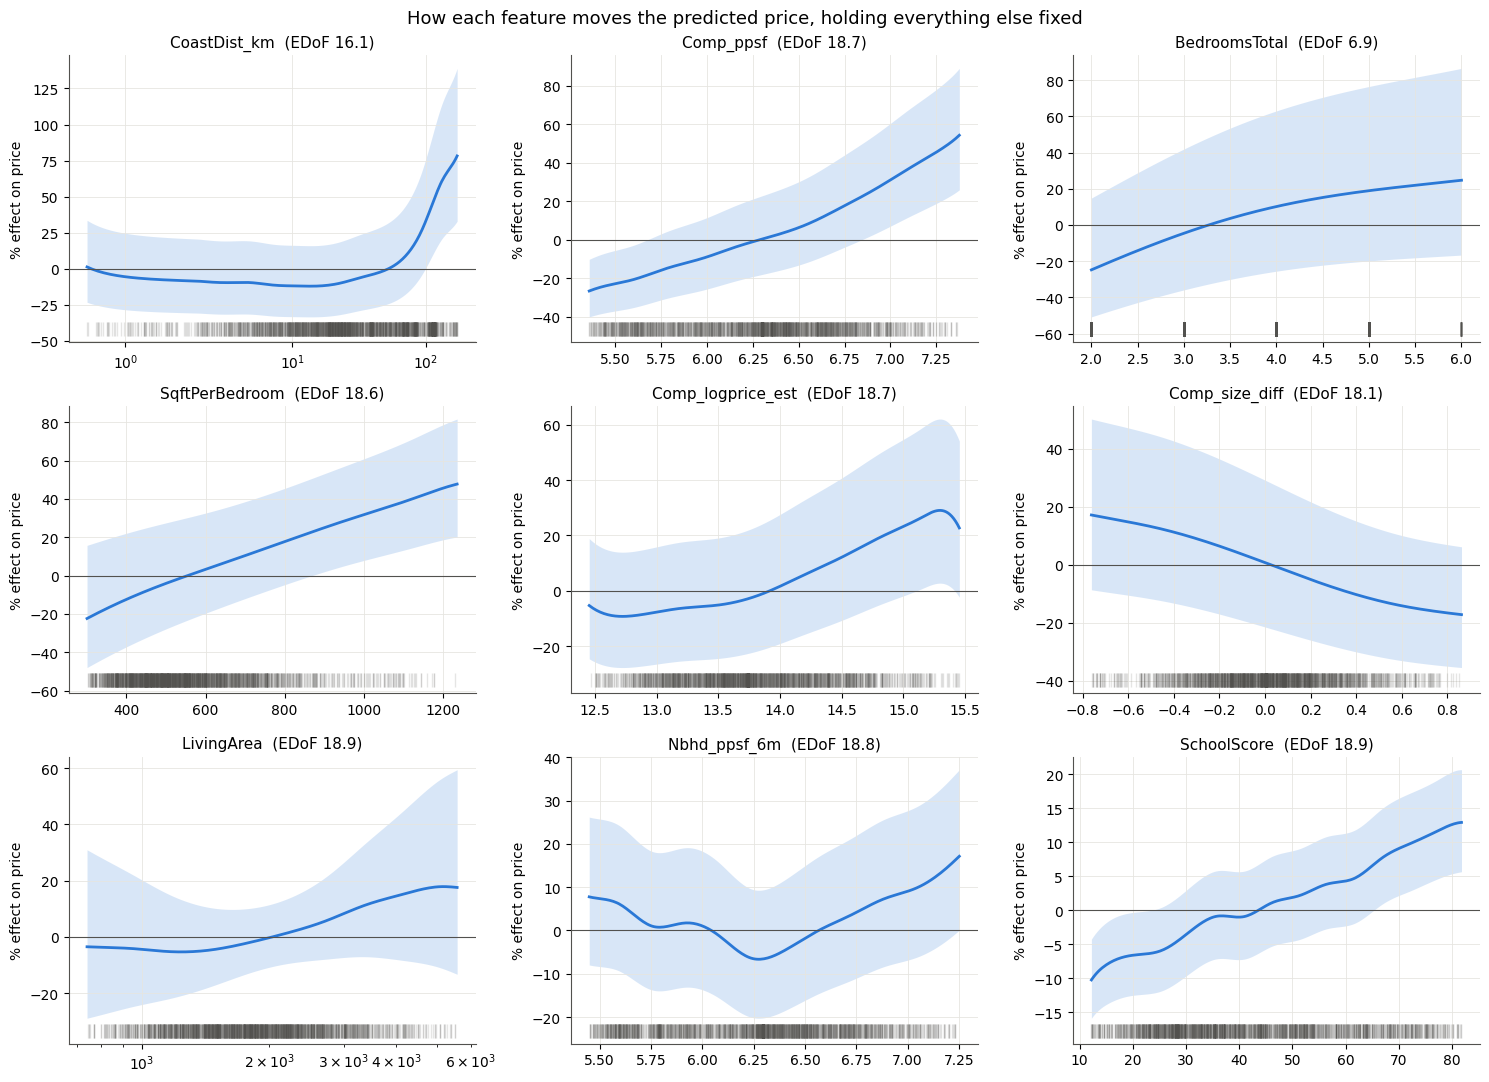

In [ ]:
def original_scale(name, x):
    # Undo the log transforms so axes read in real units
    if name.startswith('log1p_'): return np.expm1(x), name[len('log1p_'):], 'symlog'
    if name.startswith('log_'):   return np.exp(x),   name[len('log_'):],   'log'
    return x, name, 'linear'

def pct(v):
    return 100 * (np.exp(v) - 1)

top_smooth = importance[importance['type'] == 's()'].head(9)
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (_, row) in zip(axes.ravel(), top_smooth.iterrows()):
    i = int(row['term_idx'])
    j = gam.terms[i].feature
    lo, hi = np.percentile(Xtr[:, j], [1, 99])       # middle 98% of homes; the extreme edges have too few homes to read
    XX = np.repeat(Xtr[:1], 200, axis=0)            # other columns don't affect this term
    XX[:, j] = np.linspace(lo, hi, 200)
    pdep, ci = gam.partial_dependence(term=i, X=XX, width=0.95)
    center = gam.partial_dependence(term=i, X=Xtr[samp]).mean()   # 0 = the average home
    pdep, ci = pdep - center, ci - center
    x, label, scale = original_scale(feature_order[j], XX[:, j])
    ax.fill_between(x, pct(ci[:, 0]), pct(ci[:, 1]), color=BLUE, alpha=0.18, linewidth=0)
    ax.plot(x, pct(pdep), color=BLUE, linewidth=2)
    ax.axhline(0, color=INK, linewidth=0.8)
    r = Xtr[samp[:2000], j]
    rug, _, _ = original_scale(feature_order[j], r[(r >= lo) & (r <= hi)])
    ax.plot(rug, np.full(len(rug), ax.get_ylim()[0]), '|', color=INK, alpha=0.15, markersize=10)
    ax.set_xscale(scale)
    ax.set_title(f"{label}  (EDoF {row['EDoF']:.1f})", fontsize=11)
    ax.set_ylabel('% effect on price')
fig.suptitle('How each feature moves the predicted price, holding everything else fixed', fontsize=13)
fig.tight_layout()
plt.show()

**7c. Yes/no features and regions.** Factor terms are single shifts, so a bar per feature is enough.
- **Left:** the price difference for "yes" vs "no" (2 vs 1 for Stories), all else equal.
- **Right:** each `GeoCluster`'s shift compared with the average cluster. This is *on top of* the lat/lon map in 7d, so it reflects what the clusters capture that the smooth map misses.

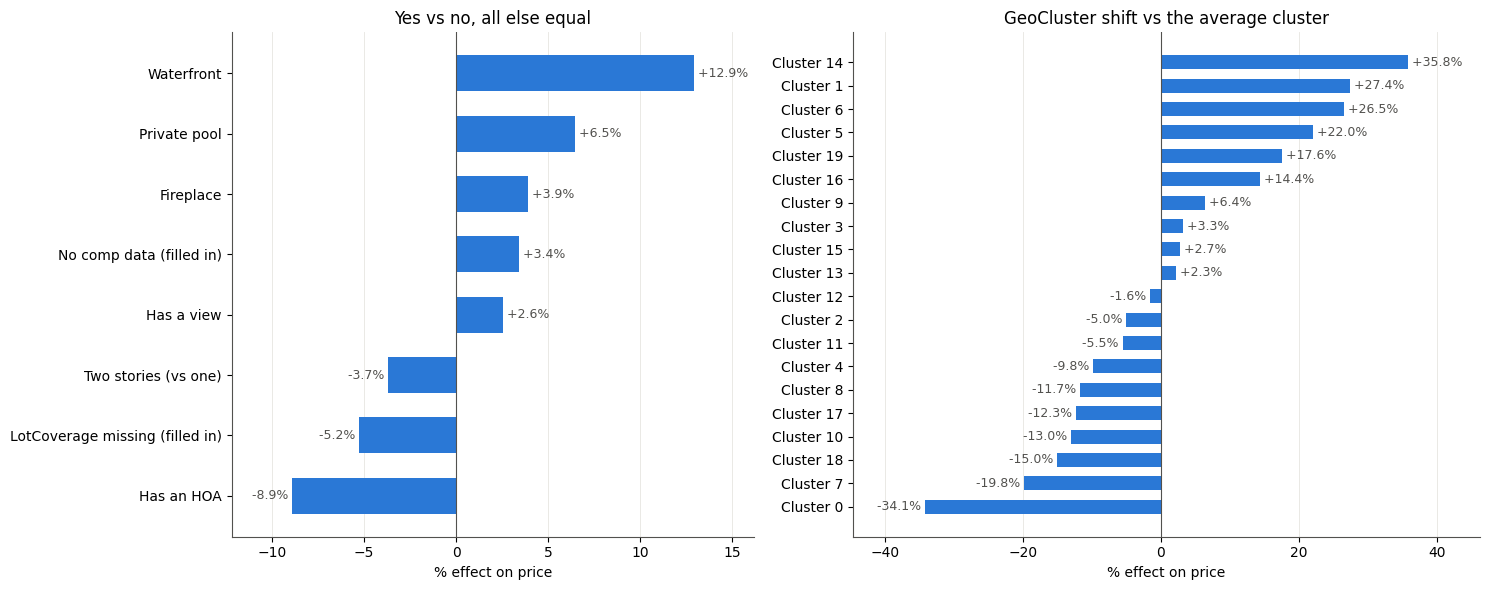

In [ ]:
def level_effects(feature, levels):
    i = next(k for k, t in enumerate(gam.terms) if not t.isintercept and np.atleast_1d(t.feature)[0] == col[feature])
    XX = np.repeat(Xtr[:1], len(levels), axis=0)
    XX[:, col[feature]] = levels
    return gam.partial_dependence(term=i, X=XX)

LABELS = {'Stories': 'Two stories (vs one)', 'ViewYN': 'Has a view', 'WaterfrontYN': 'Waterfront',
          'PoolPrivateYN': 'Private pool', 'FireplaceYN': 'Fireplace', 'HasHOA': 'Has an HOA',
          'Comp_missing': 'No comp data (filled in)'}
yes_no = pd.Series({LABELS.get(c, c.replace('_missing', ' missing (filled in)')): pct(np.diff(level_effects(c, sorted(X_train[c].unique())))[0])
                    for c in factor_cols if c != 'GeoCluster'}).sort_values()

clusters = sorted(X_train['GeoCluster'].unique())
geo_eff = level_effects('GeoCluster', clusters)
geo_eff = pd.Series(pct(geo_eff - geo_eff.mean()), index=[f'Cluster {c}' for c in clusters]).sort_values()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={'width_ratios': [1, 1.2]})
for ax, ser, title in [(a1, yes_no, 'Yes vs no, all else equal'),
                       (a2, geo_eff, 'GeoCluster shift vs the average cluster')]:
    ax.barh(ser.index, ser.values, color=BLUE, height=0.6)
    ax.axvline(0, color=INK, linewidth=0.8)
    for y, v in enumerate(ser.values):
        ax.text(v, y, f' {v:+.1f}% ' if abs(v) >= 0.05 else ' 0.0% ', va='center',
                ha='left' if v >= 0 else 'right', fontsize=9, color=INK)
    ax.set_axisbelow(True)
    ax.margins(x=0.15)                               # room for the value labels
    ax.set_xlabel('% effect on price')
    ax.set_title(title)
    ax.grid(axis='y', visible=False)
fig.tight_layout()
plt.show()

**7d. The location surface.** The `te(Latitude, Longitude)` term is a smooth price map of California. Each dot is a home from the training data, colored by how much its location alone raises (red) or lowers (blue) the predicted price compared with the average location, with size, age, comps and everything else held fixed.

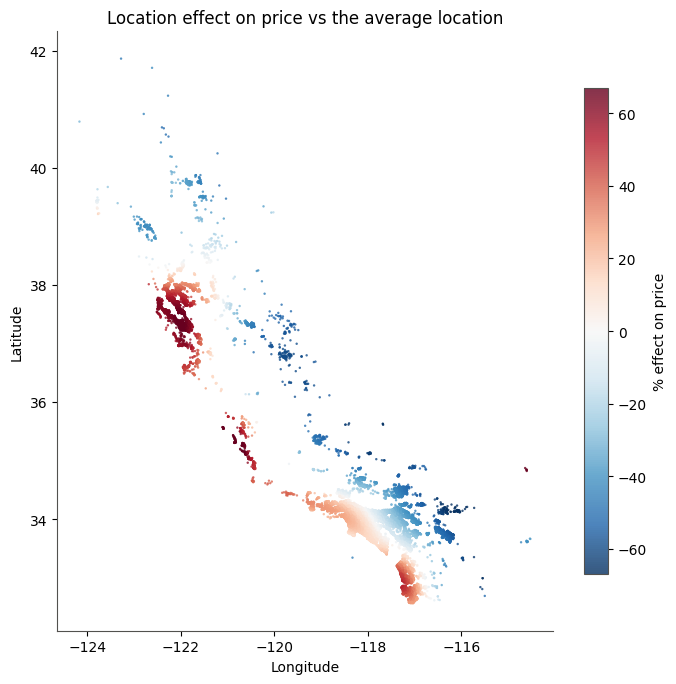

In [ ]:
i_geo = next(k for k, t in enumerate(gam.terms) if type(t).__name__ == 'TensorTerm')
pts = Xtr[samp]
loc = gam.partial_dependence(term=i_geo, X=pts)
loc_pct = pct(loc - loc.mean())
lim = np.percentile(np.abs(loc_pct), 98)

fig, ax = plt.subplots(figsize=(8, 9))
sc = ax.scatter(pts[:, col['Longitude']], pts[:, col['Latitude']], c=loc_pct, s=3, alpha=0.8,
                cmap='RdBu_r', norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(37)))   # keeps the map from looking stretched
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('Location effect on price vs the average location')
ax.grid(False)
fig.colorbar(sc, ax=ax, shrink=0.7, label='% effect on price')
plt.show()

**7e. Seasonality.** The two season terms are single slopes, so together they read best as one number: how far the listing month can push the price up or down over the year.

In [ ]:
def coef_of(feature):
    i = next(k for k, t in enumerate(gam.terms) if not t.isintercept and np.atleast_1d(t.feature)[0] == col[feature])
    return gam.coef_[gam.terms.get_coef_indices(i)][0]

season_amp = np.hypot(coef_of('ListSeason_sin'), coef_of('ListSeason_cos'))
print(f'Seasonality: listing month moves price by up to +/-{pct(season_amp):.1f}% across the year')

Seasonality: listing month moves price by up to +/-1.8% across the year


## 8. Takeaways

**Accuracy.** Test R² is **0.8777** on April 2026 sales (train 0.8695). The median home is predicted within 9.4% of its sale price, and 52.0% of homes land within 10%.

**What drives price in this model** (Section 7)
- **Location dominates.** The lat/lon map has the biggest swing (about 45%). The Bay Area, the Central Coast and coastal San Diego sit up to about 60% above the average location; the Inland Empire and Central Valley sit up to about 60% below.
- **Comparable sales and size come next:** comp price per sqft, bedrooms, sqft per bedroom, the comp price estimate and lot size.
- **Features, all else equal:** waterfront adds about 13%, a private pool 6.5%, a fireplace 3.9% and a view 2.6%.
- **Seasonality is small:** the listing month moves price by up to +/-1.8% over the year. `CloseDate` is used only to keep the train/test split in time order and is not a model feature.

**Read single curves with care when features overlap.** Several features describe the same thing:
- Size is split across living area, bedrooms and sqft per bedroom (living area is roughly bedrooms x sqft per bedroom). That is why living area alone shows a small swing (5.6%) and the bedrooms curve has a wide band.
- Location is split across the lat/lon map, `GeoCluster`, coast distance and school distances. The coast-distance curve rising far inland is most likely this overlap at work rather than a real inland premium.

The total prediction is still sound. What becomes arbitrary is how the credit is divided among overlapping features (concurvity, Section 2). Dropping or merging overlapping features would make each curve cleaner, likely at little cost in accuracy.

**Smoothing and flexibility.** The search picks `lam` = 0.001, the smallest value in the grid, and most curves use nearly all of their allowed bending. Two follow-up tests showed this isn't holding accuracy back:
- **Smaller `lam`** (down to 0.000001) improved the GCV score by under half a percent and left test R² flat (0.8772). At that point the penalty is effectively off. `lam` = 0.001 is kept because its curves are a little smoother and easier to read.
- **More splines** at `lam` = 0.001 (20 to 30 to 40 per curve) moved test R² from 0.8777 to 0.8782 to 0.8776, which is noise. 20 is kept as the simpler model.

The remaining error is not about how much each curve can bend.


**Comparing with tree models.** A random forest can score higher because it learns interactions on its own.